In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
import pandas as pd

df = pd.read_csv('/content/Sample - Superstore.csv', encoding='latin1')

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
df.shape

(9994, 21)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [ ]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Dataset Dose not Contains Any Null Values

In [ ]:
print("Duplicate Values:",df.duplicated().sum())

Duplicate Values: 0


DataSet Does Not Contains Any Duplicate Value

In [ ]:
df['Order Date']=pd.to_datetime(df['Order Date'])
df['Ship Date']=pd.to_datetime(df['Ship Date'])

In [ ]:
df['Year']=df['Order Date'].dt.year
df['Year-Month'] = df['Order Date'].dt.to_period('M')

In [ ]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Year-Month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,2016-11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,2016-11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,2016-06
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,2015-10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,2015-10


In [ ]:
print("Total Sales",df['Sales'].sum().round(2))

Total Sales 2297200.86


In [ ]:
print("Total Profit",df['Profit'].sum().round(2))

Total Profit 286397.02


In [ ]:
print("Total Order",df['Order ID'].nunique())

Total Order 5009


In [ ]:
print("Total Customer",df['Customer ID'].nunique())

Total Customer 793


In [ ]:
avg_order_Value=df.groupby('Order ID')['Sales'].sum().mean().round(2)
print("Average Order Value :",avg_order_Value)

Average Order Value : 458.61


In [ ]:
avg_order_Profit=df.groupby('Order ID')['Profit'].sum().mean().round(2)
print("Average Order Profit:",avg_order_Profit)

Average Order Profit: 57.18


Total Sales By Category


In [ ]:
cat=df.groupby('Category')['Sales'].sum().sort_values(ascending=False).round(2)
print(cat)

Category
Technology         836154.03
Furniture          741999.80
Office Supplies    719047.03
Name: Sales, dtype: float64


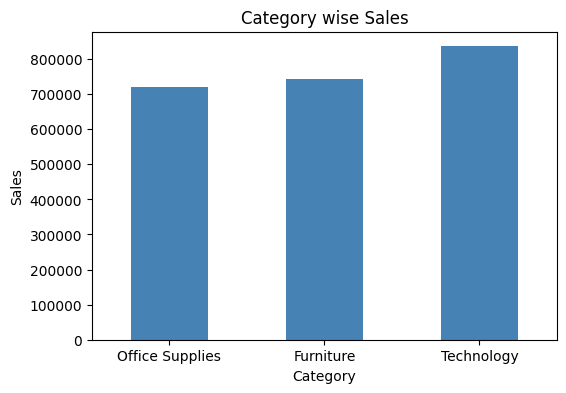

In [ ]:
cat=df.groupby('Category')['Sales'].sum().sort_values().round(2)
cat.plot(kind='bar',color="steelblue", figsize=(6, 4))
plt.title("Category wise Sales")
plt.ylabel("Sales")
plt.xticks(rotation=0)
plt.show()

 >**Insight:** All three categories contribute almost equally to sales: Technology 36.4%, Furniture 32.3% and Office Supplies 31.3%.
>
>**Why:** The business does not depend on a single category, but sales alone do not show profitability (see the profit charts below).
>
>**Recommendation:** Evaluate categories by profit and margin along with sales.

Total Profit By Category

In [ ]:
Profit_cat=df.groupby('Category')['Profit'].sum().sort_values(ascending=False).round(2)
print(Profit_cat)

Category
Technology         145454.95
Office Supplies    122490.80
Furniture           18451.27
Name: Profit, dtype: float64


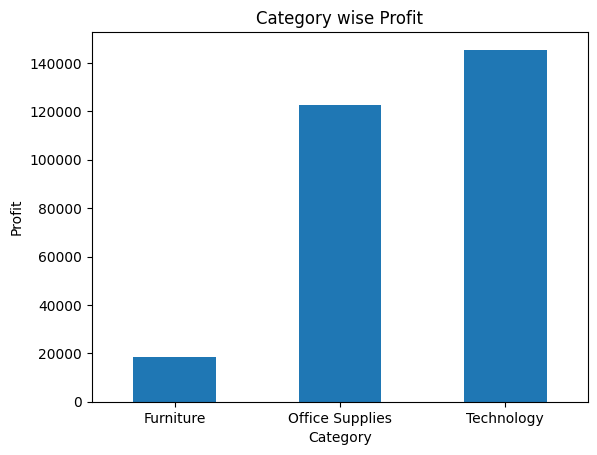

In [ ]:
Profit_cat=df.groupby('Category')['Profit'].sum().sort_values().round(2)
Profit_cat.plot(kind='bar')
plt.title("Category wise Profit")
plt.ylabel("Profit")
plt.xticks(rotation=0)
plt.show()

> **Insight:** Furniture generates 32.3% of sales but only 6.4% of profit. Technology generates 36.4% of sales and 50.8% of profit, and Office Supplies 31.3% of sales and 42.8% of profit.
>
> **Why:** Furniture has a higher average discount (17.4% vs 13.2% for Technology), and Tables and Bookcases make a loss (see the sub-category analysis).
>
> **Recommendation:** Review Furniture pricing and discount policy.


Category Wise Profit Margine

In [ ]:
cat=df.groupby('Category')['Sales'].sum()
Profit_cat=df.groupby('Category')['Profit'].sum()
Pofit_Margine_Category=(Profit_cat/cat)*100
print(Pofit_Margine_Category.round(2).sort_values(ascending=False))

Category
Technology         17.40
Office Supplies    17.04
Furniture           2.49
dtype: float64


> **Insight:** Furniture margin is only 2.49%, about 2.5 profit on every 100 of sales, compared with 17.40% for Technology and 17.04% for Office Supplies.
>
> **Why:** Tables (-8.56% margin) and Bookcases (-3.02%) lose money.
>
> **Recommendation:** Cap discounts or raise prices in Furniture.

Sub_Category Wise Sales

In [ ]:
Subcat=df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False).round(2)
print(Subcat)

Sub-Category
Phones         330007.05
Chairs         328449.10
Storage        223843.61
Tables         206965.53
Binders        203412.73
Machines       189238.63
Accessories    167380.32
Copiers        149528.03
Bookcases      114880.00
Appliances     107532.16
Furnishings     91705.16
Paper           78479.21
Supplies        46673.54
Art             27118.79
Envelopes       16476.40
Labels          12486.31
Fasteners        3024.28
Name: Sales, dtype: float64


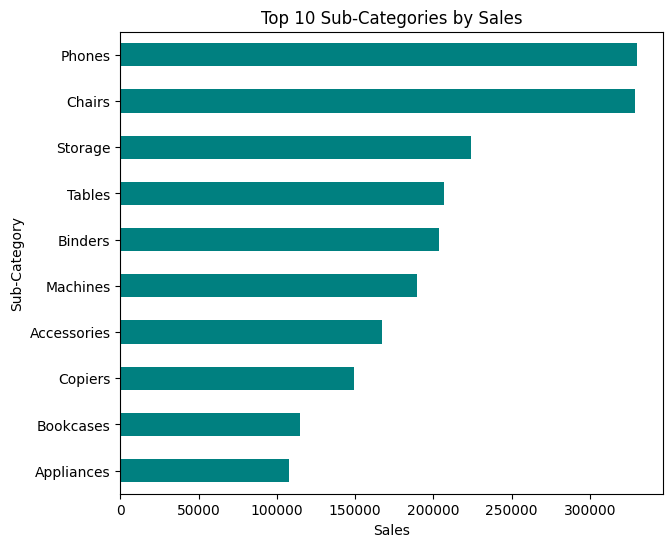

In [ ]:
Subcat=df.groupby('Sub-Category')['Sales'].sum().nlargest(10).sort_values().round(2)
Subcat.plot(kind='barh',color='teal',figsize=(7,6))
plt.title("Top 10 Sub-Categories by Sales")
plt.xlabel("Sales")
plt.show()

> **Insight:** The top three sub-categories (Phones 330,007; Chairs 328,449; Storage 223,844) together account for 38.4% of sales. Phones alone account for 14.4%.
>
> **Why:** High sales do not always mean high profit: Chairs contribute 14.3% of sales but only 9.3% of profit.
>
> **Recommendation:** Keep top sellers well stocked, but track their profit separately.

Total Profit By Sub_Category

In [ ]:
Profit_Subcat=df.groupby('Sub-Category')['Profit'].sum().sort_values(ascending=False).round(2)
print(Profit_Subcat)

Sub-Category
Copiers        55617.82
Phones         44515.73
Accessories    41936.64
Paper          34053.57
Binders        30221.76
Chairs         26590.17
Storage        21278.83
Appliances     18138.01
Furnishings    13059.14
Envelopes       6964.18
Art             6527.79
Labels          5546.25
Machines        3384.76
Fasteners        949.52
Supplies       -1189.10
Bookcases      -3472.56
Tables        -17725.48
Name: Profit, dtype: float64


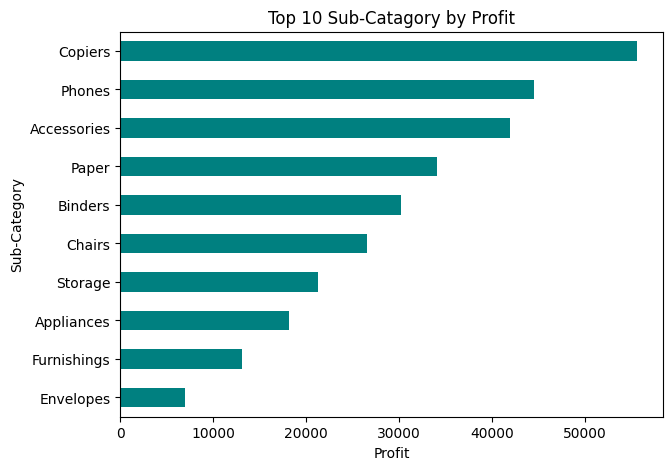

In [ ]:
Profit_Subcat=df.groupby('Sub-Category')['Profit'].sum().nlargest(10).sort_values().round(2)
Profit_Subcat.plot(kind='barh',color='teal',figsize=(7,5))
plt.title("Top 10 Sub-Catagory by Profit")
plt.xlabel("Profit")
plt.show()

> **Insight:** Copiers earn 19.4% of total profit from only 6.5% of sales (37.2% margin). Tables rank 4th in sales (206,966; 9.0%) but make a loss of -17,725. Bookcases (-3,473) and Supplies (-1,189) are also loss-making.
>
> **Why:** Tables carry an average discount of 26.1%. Tables rows with a discount above 20% lost 30,698 in total, while rows with 20% or less earned 12,973.
>
> **Recommendation:** Limit discounts on Tables and Bookcases, and promote high-margin items such as Copiers, Accessories and Paper.

In [ ]:
subcat_sales = df.groupby('Sub-Category')['Sales'].sum()
subcat_profit = df.groupby('Sub-Category')['Profit'].sum()

subcat_margin = (subcat_profit / subcat_sales) * 100

print(subcat_margin.sort_values(ascending=False).round(2))


Sub-Category
Labels         44.42
Paper          43.39
Envelopes      42.27
Copiers        37.20
Fasteners      31.40
Accessories    25.05
Art            24.07
Appliances     16.87
Binders        14.86
Furnishings    14.24
Phones         13.49
Storage         9.51
Chairs          8.10
Machines        1.79
Supplies       -2.55
Bookcases      -3.02
Tables         -8.56
dtype: float64


> **Insight:** The highest margins are Labels (44.42%), Paper (43.39%), Envelopes (42.27%) and Copiers (37.20%). Labels and Envelopes each contribute less than 1% of sales. Binders contribute 8.9% of sales with a 14.86% margin.
>
> **Why:** Labels, Paper and Envelopes are sold at an average discount of only 7-8%.
>
> **Recommendation:** Grow sales of high-margin items (bundles, promotions) and fix the pricing of Tables, Bookcases and Supplies.

City Wise Sales


In [ ]:
city_Sale=df.groupby('City')['Sales'].sum().nlargest(10)
print(city_Sale.round(2))

City
New York City    256368.16
Los Angeles      175851.34
Seattle          119540.74
San Francisco    112669.09
Philadelphia     109077.01
Houston           64504.76
Chicago           48539.54
San Diego         47521.03
Jacksonville      44713.18
Springfield       43054.34
Name: Sales, dtype: float64


> **Insight:** New York City is the largest city (256,368; 11.2% of sales), followed by Los Angeles (175,851) and Seattle (119,541). The top 10 cities contribute 44.5% of sales, but 4 of them are loss-making: Philadelphia (-13,838), Houston (-10,154), Chicago (-6,655) and Jacksonville (-2,324).
>
> **Why:** These cities are in Pennsylvania, Texas, Illinois and Florida, states with average discounts of about 30-39%.
>
> **Recommendation:** Apply discount limits in these cities and review city-level profit, not just sales.

 Segment Wise Sales

In [ ]:
Sagment_Sale=df.groupby('Segment')['Sales'].sum().sort_values(ascending=False).round(2)
print(Sagment_Sale)

Segment
Consumer       1161401.34
Corporate       706146.37
Home Office     429653.15
Name: Sales, dtype: float64


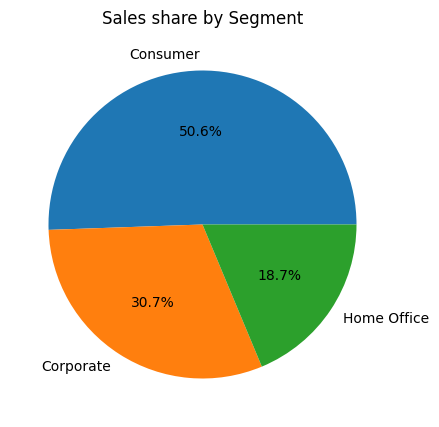

In [ ]:
Sagment_Sale.plot(kind='pie',autopct="%1.1f%%", figsize=(5, 5))
plt.title("Sales share by Segment")
plt.ylabel("")
plt.show()

> **Insight:** Consumer contributes 50.6% of sales, Corporate 30.7% and Home Office 18.7%.
>
> **Recommendation:** Consumer is the largest customer base, so its margin matters most (see below).

Segment Wise Profit

In [ ]:
Sagment_Profit=df.groupby('Segment')['Profit'].sum().sort_values(ascending=False).round(2)
print(Sagment_Profit)

Segment
Consumer       134119.21
Corporate       91979.13
Home Office     60298.68
Name: Profit, dtype: float64


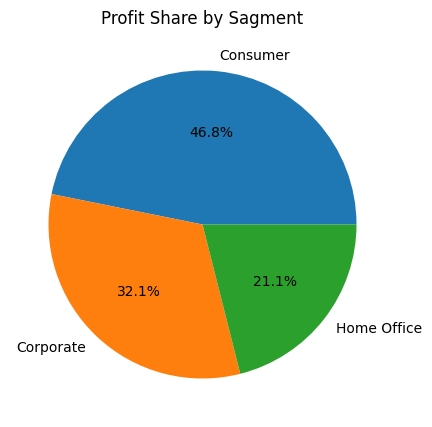

In [ ]:
Sagment_Profit.plot(kind='pie',autopct='%1.1f%%',figsize=(5,5))
plt.title("Profit Share by Sagment")
plt.ylabel("")
plt.show()

> **Insight:** Profit share: Consumer 46.8%, Corporate 32.1%, Home Office 21.1%. Consumer's profit share is lower than its sales share (50.6%), while Home Office's profit share (21.1%) is higher than its sales share (18.7%).
>
> **Why:** Home Office is the smallest segment but the most profitable per sale.
>
> **Recommendation:** Look for ways to grow the Home Office segment.

 Segment Wise Profit Margine


In [ ]:
Profit_Margen_Sagment=(Sagment_Profit/Sagment_Sale)*100
print(Profit_Margen_Sagment.round(2).sort_values(ascending=False))

Segment
Home Office    14.03
Corporate      13.03
Consumer       11.55
dtype: float64


> **Insight:** Margin: Home Office 14.03%, Corporate 13.03%, Consumer 11.55%. The largest segment has the lowest margin.
>
> **Why:** Average discount is almost the same across segments (14.7% to 15.8%), so the gap is likely due to product mix or region rather than discount.
>
> **Recommendation:** Drill down into Consumer by sub-category and state to find what pulls its margin down.

Region Wise Sales

In [ ]:
Region_Sale=df.groupby('Region')['Sales'].sum().round(2)
print(Region_Sale.sort_values(ascending=False))

Region
West       725457.82
East       678781.24
Central    501239.89
South      391721.90
Name: Sales, dtype: float64


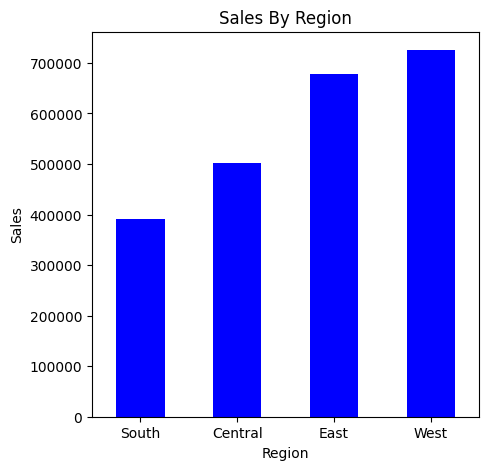

In [ ]:
Region_Sale=df.groupby('Region')['Sales'].sum().sort_values().round(2)
Region_Sale.plot(kind='bar',color='blue',figsize=(5,5))
plt.title("Sales By Region")
plt.xticks(rotation=0)
plt.ylabel("Sales")
plt.show()

> **Insight:** West is the top region (725,458; 31.6% of sales), followed by East (678,781), Central (501,240) and South (391,722).

Region Wise Profit

In [ ]:
Region_Profit=df.groupby('Region')['Profit'].sum().round(2)
print(Region_Profit.sort_values(ascending=False))

Region
West       108418.45
East        91522.78
South       46749.43
Central     39706.36
Name: Profit, dtype: float64


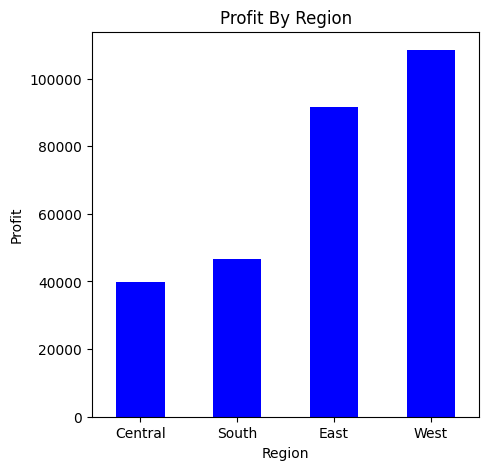

In [ ]:
Region_Profit=df.groupby('Region')['Profit'].sum().sort_values().round(2)
Region_Profit.plot(kind='bar',color='blue',figsize=(5,5))
plt.title("Profit By Region")
plt.xticks(rotation=0)
plt.ylabel("Profit")
plt.show()

> **Insight:** West gives the most profit (108,418; 37.9% share). Central has 21.8% of sales but only 13.9% of profit.

Region Wise Profit Margin

In [ ]:
Region_Sale=df.groupby('Region')['Sales'].sum().round(2)
Region_Profit=df.groupby('Region')['Profit'].sum().round(2)
Profit_Margin_Region=(Region_Profit/Region_Sale)*100
print(Profit_Margin_Region.round(2).sort_values(ascending=False))

Region
West       14.94
East       13.48
South      11.93
Central     7.92
dtype: float64


> **Insight:** Margin: West 14.94%, East 13.48%, South 11.93%, Central 7.92%.
>
> **Why:** Central's average discount is 24.0% (West 10.9%), and 27.7% of Central's rows have a discount of 30% or more (West 3.7%).
>
> **Recommendation:** Fix the discount policy in Central first; it is the biggest regional gap.

Yearly Sales


In [ ]:
Yearly_Sales=df.groupby('Year')['Sales'].sum().round(2)
print(Yearly_Sales.sort_values(ascending=False))

Year
2017    733215.26
2016    609205.60
2014    484247.50
2015    470532.51
Name: Sales, dtype: float64


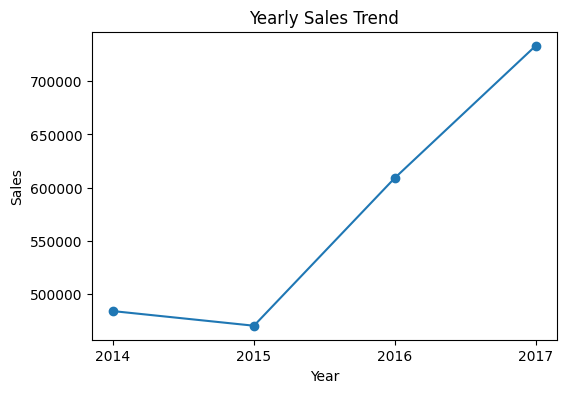

In [ ]:
Yearly_Sales.plot(kind='line',marker="o",figsize=(6, 4))
plt.title("Yearly Sales Trend")
plt.ylabel("Sales")
plt.xticks(Yearly_Sales.index)
plt.show()

> **Insight:** Sales grew from 484,248 in 2014 to 733,215 in 2017 (+51.4%). After a small dip in 2015 (-2.83%), growth was strong in 2016 (+29.47%) and 2017 (+20.36%).

Sales Wise Year-on-Year Growth  %

In [ ]:
YYG=Yearly_Sales.pct_change()*100
print(YYG)

Year
2014          NaN
2015    -2.832227
2016    29.471522
2017    20.355962
Name: Sales, dtype: float64


Year Wise Profit

In [ ]:
Yearly_Profit=df.groupby('Year')['Profit'].sum().round(2)
print(Yearly_Profit.sort_values(ascending=False))

Year
2017    93439.27
2016    81795.17
2015    61618.60
2014    49543.97
Name: Profit, dtype: float64


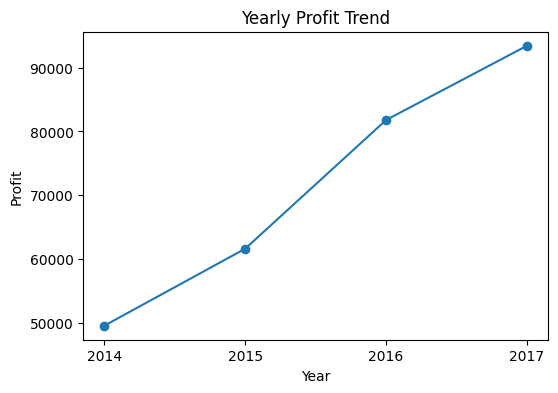

In [ ]:
Yearly_Profit.plot(kind='line',marker="o",figsize=(6, 4))
plt.title("Yearly Profit Trend")
plt.ylabel("Profit")
plt.xticks(Yearly_Sales.index)
plt.show()

> **Insight:** Profit grew from 49,544 in 2014 to 93,439 in 2017 (+88.6%), faster than sales.

Profit Wise Year-on-Year Growth %

In [ ]:
YYGP=Yearly_Profit.pct_change()*100
print(YYGP)

Year
2014          NaN
2015    24.371543
2016    32.744285
2017    14.235682
Name: Profit, dtype: float64


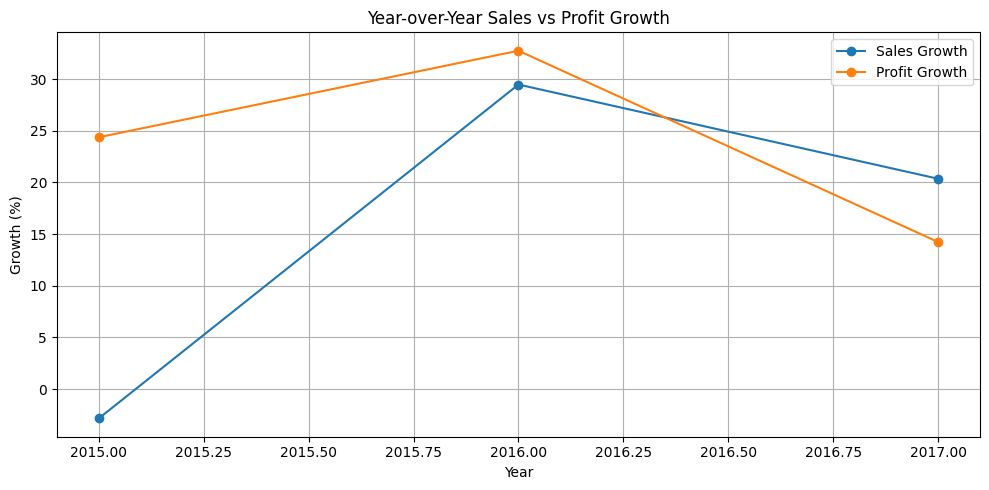

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(YYG.index, YYG.values,
         marker='o', label='Sales Growth')

plt.plot(YYGP.index,YYGP.values,
         marker='o', label='Profit Growth')

plt.title('Year-over-Year Sales vs Profit Growth')
plt.xlabel('Year')
plt.ylabel('Growth (%)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

> **Insight:** In 2015 sales fell 2.83% but profit rose 24.37%. In 2016 both grew strongly (+29.47% and +32.74%). In 2017 sales grew 20.36% but profit growth slowed to 14.24%.
>
> **Why:** In 2015 the average discount was flat (15.8% to 15.6%); margin improved because Technology (12.3% to 20.6%) and Office Supplies (14.9% to 18.3%) became more profitable. In 2017 Machines made a loss of 2,869 and Furniture margin was 1.4%.
>
> **Recommendation:** Track margin along with sales growth; growth in 2017 was less profitable.

Year Wise Profit_Margin

In [ ]:
Yearly_profit_Margin=(Yearly_Profit/Yearly_Sales)*100
print(Yearly_profit_Margin.round(2).sort_values(ascending=False))

Year
2016    13.43
2015    13.10
2017    12.74
2014    10.23
dtype: float64


> **Insight:** Margin: 2014 10.23%, 2015 13.10%, 2016 13.43%, 2017 12.74%. In 2017 sales grew 20.36% but margin fell by 0.69 percentage points.
>
> **Recommendation:** Track margin monthly to catch declines early.

Montly Wise Sales and Profit

In [ ]:
monthly_trend = df.groupby('Year-Month').agg({
    'Sales': 'sum',
    'Profit': 'sum'
})
print(monthly_trend)

                  Sales      Profit
Year-Month                         
2014-01      14236.8950   2450.1907
2014-02       4519.8920    862.3084
2014-03      55691.0090    498.7299
2014-04      28295.3450   3488.8352
2014-05      23648.2870   2738.7096
2014-06      34595.1276   4976.5244
2014-07      33946.3930   -841.4826
2014-08      27909.4685   5318.1050
2014-09      81777.3508   8328.0994
2014-10      31453.3930   3448.2573
2014-11      78628.7167   9292.1269
2014-12      69545.6205   8983.5699
2015-01      18174.0756  -3281.0070
2015-02      11951.4110   2813.8508
2015-03      38726.2520   9732.0978
2015-04      34195.2085   4187.4962
2015-05      30131.6865   4667.8690
2015-06      24797.2920   3335.5572
2015-07      28765.3250   3288.6483
2015-08      36898.3322   5355.8084
2015-09      64595.9180   8209.1627
2015-10      31404.9235   2817.3660
2015-11      75972.5635  12474.7884
2015-12      74919.5212   8016.9659
2016-01      18542.4910   2824.8233
2016-02      22978.8150   50

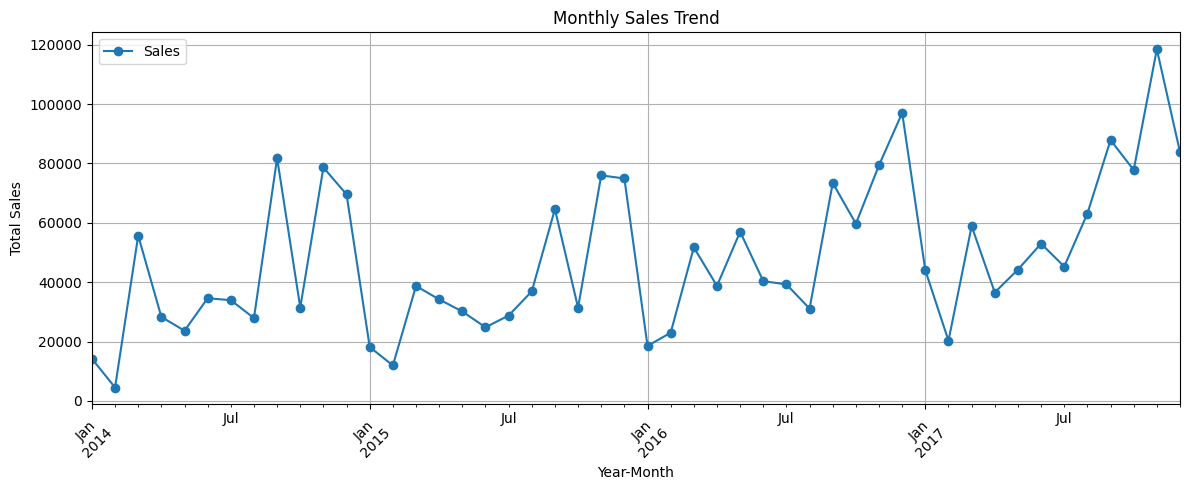

In [ ]:
monthly_trend.plot(
    y='Sales',
    figsize=(12, 5),
    marker='o',
    title='Monthly Sales Trend'
)

plt.xlabel('Year-Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

> **Insight:** In every year the three busiest months are September, November and December. The highest month is November 2017 (118,448), followed by December 2016 (96,999) and September 2017 (87,867). The weakest months are in January-February (Feb 2014: 4,520). September-December together contribute 51.6% of sales.
>
> **Recommendation:** Plan stock and staffing for September-December in advance, and use promotions to lift January-February.

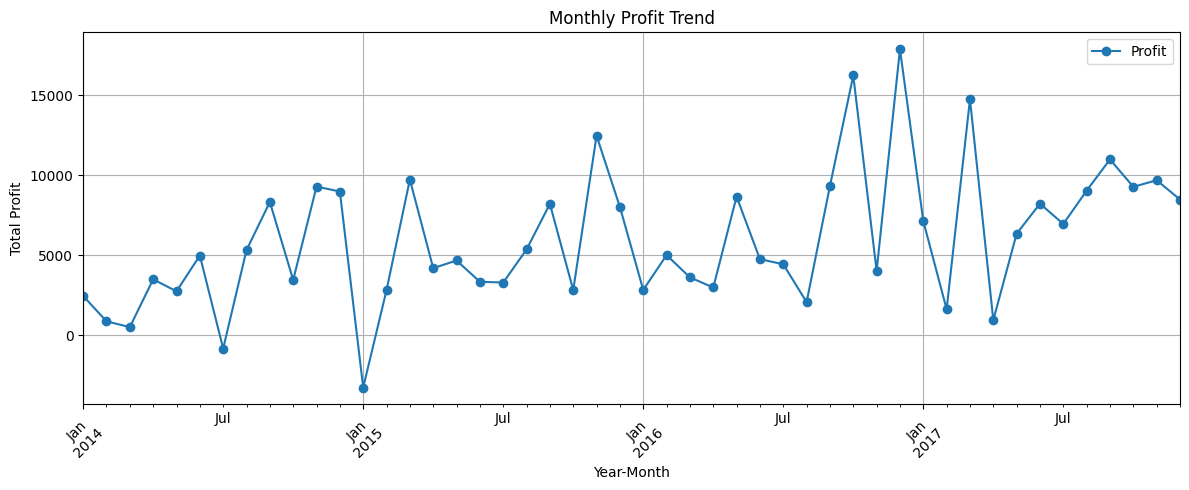

In [ ]:
monthly_trend.plot(
    y='Profit',
    figsize=(12, 5),
    marker='o',
    title='Monthly Profit Trend'
)

plt.xlabel('Year-Month')
plt.ylabel('Total Profit')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

> **Insight:** The highest profit months are December 2016 (17,885), October 2016 (16,243) and March 2017 (14,752). Only 2 months made a loss: January 2015 (-3,281) and July 2014 (-841).
>
> **Recommendation:** Drill down into January 2015 (products and discounts) to find the cause of the loss.

Most Saled 10 Product


In [ ]:
MSP=df.groupby(['Product ID','Product Name'])['Quantity'].sum().nlargest(10)
print(MSP)

Product ID       Product Name                                              
OFF-BI-10001524  GBC Premium Transparent Covers with Diagonal Lined Pattern    67
FUR-CH-10002647  Situations Contoured Folding Chairs, 4/Set                    64
FUR-TA-10001095  Chromcraft Round Conference Tables                            61
FUR-CH-10003774  Global Wood Trimmed Manager's Task Chair, Khaki               59
OFF-BI-10004728  Wilson Jones Turn Tabs Binder Tool for Ring Binders           59
TEC-AC-10003038  Kingston Digital DataTraveler 16GB USB 2.0                    57
OFF-ST-10001809  Fellowes Officeware Wire Shelving                             55
FUR-CH-10002880  Global High-Back Leather Tilter, Burgundy                     54
FUR-CH-10004287  SAFCO Arco Folding Chair                                      53
OFF-PA-10003441  Xerox 226                                                     53
Name: Quantity, dtype: int64


> **Insight:** The best-selling product is GBC Premium Transparent Covers (67 units). 4 of the top 10 products by quantity are loss-making: Chromcraft Round Conference Tables (-190), Global Wood Trimmed Manager's Task Chair (-503), Fellowes Officeware Wire Shelving (-332) and Global High-Back Leather Tilter (-475).
>
> **Why:** High quantity does not guarantee profit.
>
> **Recommendation:** Check the profit of best-sellers separately.

Discount Vs Sales Vs Profit Vs Avg Profit


In [ ]:
discount_profit = df.groupby('Discount').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Average_Profit=('Profit', 'mean'),
    Order_Count=('Profit', 'count')
).round(2)

discount_profit

,Total_Sales,Total_Profit,Average_Profit,Order_Count
Discount,,,,
0.00,1087908.47,320987.60,66.90,4798
0.10,54369.35,9029.18,96.06,94
0.15,27558.52,1418.99,27.29,52
0.20,764594.37,90337.31,24.70,3657
0.30,103226.66,-10369.28,-45.68,227
0.32,14493.46,-2391.14,-88.56,27
0.40,116417.78,-23057.05,-111.93,206
0.45,5484.97,-2493.11,-226.65,11
0.50,58918.54,-20506.43,-310.70,66


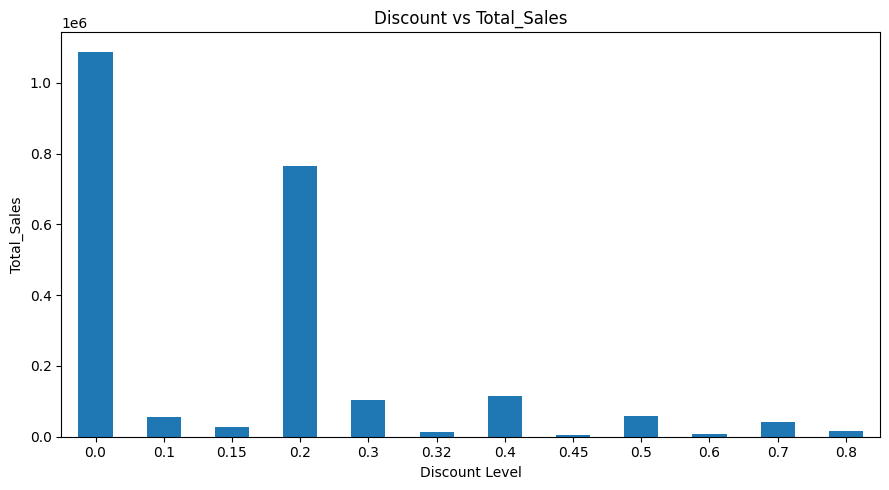

In [ ]:

discount_profit['Total_Sales'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Discount vs Total_Sales'
)

plt.xlabel('Discount Level')
plt.ylabel('Total_Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


> **Insight:** 80.6% of sales come from just two discount levels: no discount (4,798 rows) and 20% (3,657 rows).

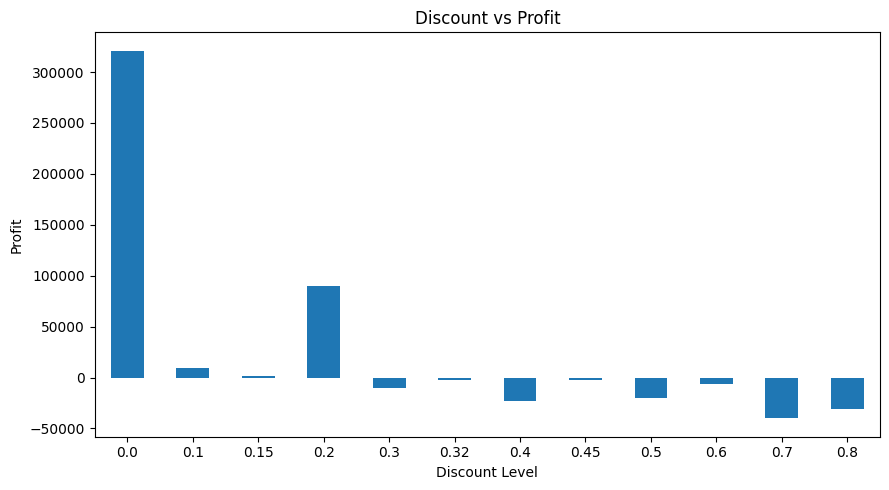

In [ ]:
discount_profit['Total_Profit'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Discount vs Profit'
)

plt.xlabel('Discount Level')
plt.ylabel('Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


> **Insight:** Total profit is positive only at 0% (+320,988), 10% (+9,029), 15% (+1,419) and 20% (+90,337). Every level from 30% upward is negative, with the largest losses at 70% (-40,075) and 80% (-30,539).

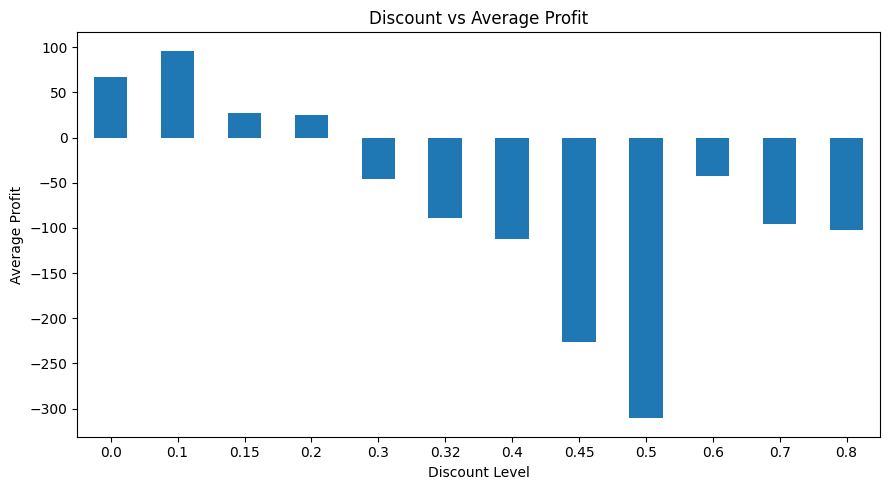

In [ ]:

discount_profit['Average_Profit'].plot(
    kind='bar',
    figsize=(9, 5),
    title='Discount vs Average Profit'
)

plt.xlabel('Discount Level')
plt.ylabel('Average Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


> **Insight:** Average profit per row is +66.90 at 0% discount and +24.70 at 20%. It turns to -45.68 at 30% and falls to -310.70 at 50%.

In [ ]:
ProfitMargin_Dicount=(discount_profit['Total_Profit']/discount_profit['Total_Sales'])*100
print(ProfitMargin_Dicount.sort_values(ascending=False).round(2))

Discount
0.00     29.51
0.10     16.61
0.20     11.82
0.15      5.15
0.30    -10.05
0.32    -16.50
0.40    -19.81
0.50    -34.80
0.45    -45.45
0.60    -89.46
0.70    -98.66
0.80   -180.03
dtype: float64


> **Insight:** Margin falls from 29.51% (no discount) to 11.82% (20%), -10.05% (30%) and -180.03% (80%). The correlation between discount and profit is -0.219.
>
> **Why:** At high discounts the selling price appears to fall below cost (the dataset has no cost column, so this cannot be confirmed).
>
> **Recommendation:** Cap discounts at 20%; margin stays positive up to that level (11.82%).

In [ ]:
product_profit = df.groupby('Product Name')['Profit'].sum()

product_profit

,Profit
Product Name,
"""While you Were Out"" Message Book, One Form per Page",10.3880
"#10 Gummed Flap White Envelopes, 100/Box",16.7678
#10 Self-Seal White Envelopes,52.1230
"#10 White Business Envelopes,4 1/8 x 9 1/2",223.1408
"#10- 4 1/8"" x 9 1/2"" Recycled Envelopes",115.2806
...,...
"iKross Bluetooth Portable Keyboard + Cell Phone Stand Holder + Brush for Apple iPhone 5S 5C 5, 4S 4",115.6440
iOttie HLCRIO102 Car Mount,-11.9940
iOttie XL Car Mount,-50.3748


In [ ]:
loss_products = product_profit[product_profit < 0]

loss_products.sort_values().round(2).head(10)

,Profit
Product Name,
Cubify CubeX 3D Printer Double Head Print,-8879.97
Lexmark MX611dhe Monochrome Laser Printer,-4589.97
Cubify CubeX 3D Printer Triple Head Print,-3839.99
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,-2876.12
Bush Advantage Collection Racetrack Conference Table,-1934.40
GBC DocuBind P400 Electric Binding System,-1878.17
Cisco TelePresence System EX90 Videoconferencing Unit,-1811.08
Martin Yale Chadless Opener Electric Letter Opener,-1299.18
Balt Solid Wood Round Tables,-1201.06


> **Insight:** 301 of 1,850 products (grouped by name) are loss-making, with a total loss of -77,068. The largest are Cubify CubeX 3D Printer Double Head (-8,880), Lexmark MX611dhe Monochrome Laser Printer (-4,590) and Cubify CubeX 3D Printer Triple Head (-3,840).
>
> **Why:** The two Cubify CubeX Double Head orders sold at a 70% discount lost 9,240 in total.
>
> **Recommendation:** Add an approval rule for large discounts on Machines and Tables.